# 20 – LSTM: ein Netz lernt den Normalbetrieb und findet dabei Fehler

**Zweck:** Die Kennzahlen aus Notebook 18 hat jemand ausgesucht. Ein neuronales Netz
kann aus den Stundenwerten selbst lernen, was das Verhalten einer Station ausmacht —
ohne dass vorher feststeht, worauf es ankommt, und **ohne Labels**.

**Die Idee in drei Schritten**

1. Ein LSTM liest einen Tag einer Station (24 Stunden, sechs Größen) und soll daraus
   den **nächsten Tag vorhersagen**. Dazwischen muss es den Tag durch einen Engpass
   aus **acht Zahlen** schicken — das *Embedding*.
2. Um gut vorherzusagen, muss das Netz in diese acht Zahlen packen, wie die Station
   tickt: Regelt sie sauber? Läuft nachts Wasser durch? Kühlt sie gut aus?
3. Das mittlere Embedding einer Station über einen Winter ist dann eine Beschreibung
   der Station — und darauf lernt eine **logistische Regression**, welche Stationen
   bei der Begehung einen Befund hatten.

Trainiert wird nur auf Tagen **vor** den Begehungen. Die Architektur (LSTM mit 96
Einheiten, Embedding mit 8 Zahlen, Aufgabe „nächsten Tag vorhersagen“) stammt aus
einer Vorarbeit, in der 24 Varianten verglichen und **ohne Labels** ausgewählt wurden —
über die Wiedererkennung in Abschnitt 6.

| Notebook | liefert |
|---|---|
| [`18_modelldaten`](18_modelldaten_labels.ipynb) | Stundenwerte mit Außentemperatur, Kennzahlen, Labels |

**Ergebnis:** `lstm_embedding.csv` (Embeddings je Zähler), `lstm_scores.csv`
(Vorhersagen aus der Prüfung), Modellgewichte in `notebooks/models/`.

## 1 · Setup

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
NEU_TRAINIEREN = False      # True: Gewichte ignorieren und neu lernen
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.11.0+cu128, gerechnet auf: cuda


**Was macht diese Zelle?**
- Lädt PyTorch für das Netz und scikit-learn für die Prüfung.
- `NEU_TRAINIEREN = False` heißt: Liegen schon Gewichte in `notebooks/models/`, werden sie
  geladen statt neu gelernt. Der Ordner ist gitignored, beim ersten Lauf auf einem neuen
  Rechner wird also immer trainiert.
- Gerechnet wird auf der Grafikkarte, wenn es eine gibt. Ohne GPU läuft alles auch auf der
  CPU, nur langsamer.

## 2 · Daten: vollständige Tage als Feld

Das Netz liest Tage. Jeder vollständige Tag wird zu einer Tabelle mit 24 Zeilen
(Stunden) und 6 Spalten (Größen). Alle Tage zusammen ergeben ein dreidimensionales
Feld: Tage × 24 × 6.

In [2]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")

KANAELE = ["leistung", "durchfluss", "spreizung", "vorlauf", "ruecklauf", "aussen"]
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
voll = stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24
stunden = stunden[voll].sort_values(["zaehler", "timestamp"])

werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

# Je Zähler: bis wann gilt "vor der Begehung"?
grenze = labels["erste_begehung"].clip(upper=STICHTAG)
tage["vorher"] = tage["tag"] < tage["zaehler"].map(grenze).fillna(STICHTAG)
print(f"Feld: {werte.shape[0]:,} Tage × {werte.shape[1]} Stunden × {werte.shape[2]} Größen")
print(f"davon vor der Begehung: {tage['vorher'].sum():,}")
tage.head()

Feld: 69,879 Tage × 24 Stunden × 6 Größen
davon vor der Begehung: 41,913


,zaehler,tag,vorher
0,41704231,2022-11-13,True
1,41704231,2022-11-14,True
2,41704231,2022-11-15,True
3,41704231,2022-11-16,True
4,41704231,2022-11-17,True


**Was macht diese Zelle?**
- Wirft Stunden mit fehlenden Werten weg und behält nur Tage, an denen alle 24 Stunden übrig
  bleiben.
- `reshape(-1, 24, 6)` macht aus der langen Stundentabelle das Feld: Weil die Tabelle nach
  Zähler und Zeit sortiert ist, stehen immer 24 Zeilen hintereinander, die einen Tag bilden.
- `tage` merkt sich zu jedem Eintrag im Feld Zähler und Datum, und ob der Tag vor der ersten
  Begehung des Zählers liegt.

### Skalierung

Neuronale Netze lernen schlecht, wenn eine Größe in Hunderten (Durchfluss) und die
andere in Zehnern (Temperatur) gemessen wird. Zwei Regeln:

* **Leistung und Durchfluss je Zähler**, geteilt durch das 95-%-Quantil des Zählers.
  Ein Mehrfamilienhaus und ein kleines Einfamilienhaus sollen dasselbe Verhalten auch
  gleich aussehen lassen.
* **Temperaturen und Spreizung für alle gleich** standardisiert. 65 °C Rücklauf ist in
  jedem Haus schlecht — das soll das Netz sehen.

Alle Skalen kommen nur aus Tagen vor den Begehungen.

In [3]:
x = werte.copy()
vorher = tage["vorher"].to_numpy()
stunde_vorher = np.repeat(vorher, 24)          # dieselbe Markierung je Stunde (gleiche Reihenfolge wie im Feld)
teiler, mittel, streuung, skalen = {}, {}, {}, {}
for i, kanal in enumerate(KANAELE):
    if kanal in ("leistung", "durchfluss"):
        teiler[kanal] = stunden[stunde_vorher].groupby("zaehler")[kanal].quantile(0.95).clip(lower=1e-3)
        je_tag = tage["zaehler"].map(teiler[kanal]).fillna(1.0).to_numpy(dtype=np.float32)
        x[:, :, i] = werte[:, :, i] / je_tag[:, None]
        skalen[kanal] = "Wert / 95-%-Quantil des Zählers"
    else:
        mittel[kanal], streuung[kanal] = werte[vorher, :, i].mean(), werte[vorher, :, i].std()
        x[:, :, i] = (werte[:, :, i] - mittel[kanal]) / streuung[kanal]
        skalen[kanal] = f"(Wert − {mittel[kanal]:.1f}) / {streuung[kanal]:.1f}"
pd.DataFrame({"Skalierung": pd.Series(skalen),
              "Mittel danach": pd.Series(x[vorher].mean(axis=(0, 1)), index=KANAELE).round(2),
              "Streuung danach": pd.Series(x[vorher].std(axis=(0, 1)), index=KANAELE).round(2)})

,Skalierung,Mittel danach,Streuung danach
leistung,Wert / 95-%-Quantil des Zählers,0.27,0.37
durchfluss,Wert / 95-%-Quantil des Zählers,0.34,0.40
spreizung,(Wert − 15.3) / 13.8,0.00,1.00
vorlauf,(Wert − 62.4) / 16.0,-0.00,1.00
ruecklauf,(Wert − 47.1) / 15.7,-0.00,1.00
aussen,(Wert − 11.7) / 8.3,-0.00,1.00


**Was macht diese Zelle?**
- Für Leistung und Durchfluss: Je Zähler wird das 95-%-Quantil aller Stundenwerte vor der
  Begehung bestimmt und jeder Wert dadurch geteilt. Typische Werte liegen danach zwischen 0 und 1.
- Für die Temperaturen: Mittelwert abziehen, durch die Streuung teilen, mit denselben zwei
  Zahlen für alle Zähler.
- Die Tabelle zeigt die Rechnung und kontrolliert das Ergebnis.

### Paare: heute → morgen

Die Aufgabe heißt „aus heute morgen vorhersagen“. Gebraucht werden also Paare aus zwei
**aufeinanderfolgenden** vollständigen Tagen desselben Zählers. Das Netz bekommt
heute komplett und von morgen nur die Außentemperatur — die ist bekannt (Wetterbericht),
das Verhalten der Station nicht.

Für das Lernen gibt es zwei Töpfe: **Training** und **Validierung**. Validiert wird auf
ganzen Kalenderwochen, nicht auf einzelnen Tagen: Der 14. Januar einer Station gleicht
dem 13. fast aufs Haar — läge nur er in der Validierung, wäre sie zu leicht.

In [4]:
folgetag = (tage["zaehler"].shift(-1) == tage["zaehler"]) & (tage["tag"].shift(-1) == tage["tag"] + pd.Timedelta(days=1))
heute = np.flatnonzero(folgetag.to_numpy() & np.roll(vorher, -1) & vorher)
morgen = heute + 1

woche = tage.loc[morgen, "tag"].dt.to_period("W").astype(str).to_numpy()
alle_wochen = np.unique(woche)
val_wochen = np.random.default_rng(SEED).choice(alle_wochen, size=int(0.1 * len(alle_wochen)), replace=False)
ist_val = np.isin(woche, val_wochen)

eingang = torch.tensor(x[heute])
ziel = torch.tensor(x[morgen][:, :, :5])
aussen_morgen = torch.tensor(x[morgen][:, :, 5:])
print(f"{len(heute):,} Paare heute→morgen, davon {ist_val.sum():,} in {len(val_wochen)} Validierungswochen")
print(f"Eingang {tuple(eingang.shape)}, Ziel {tuple(ziel.shape)}, Außentemperatur morgen {tuple(aussen_morgen.shape)}")

41,113 Paare heute→morgen, davon 3,449 in 9 Validierungswochen
Eingang (41113, 24, 6), Ziel (41113, 24, 5), Außentemperatur morgen (41113, 24, 1)


**Was macht diese Zelle?**
- `folgetag` ist wahr, wenn der nächste Eintrag im Feld derselbe Zähler am nächsten
  Kalendertag ist. Nur dann ist es ein echtes Paar.
- Beide Tage müssen vor der Begehung liegen.
- 10 % der Kalenderwochen werden zufällig zur Validierung bestimmt.
- Das Ziel sind die fünf Stationsgrößen von morgen. Die Außentemperatur von morgen ist
  Eingang, nicht Ziel.

## 3 · Das Netz

```
heute (24 × 6) ──► LSTM-Encoder (96) ──► 8 Zahlen = Embedding
                                              │
          Außentemperatur morgen (24 × 1) ──► LSTM-Decoder (96) ──► morgen (24 × 5)
```

Der **Encoder** liest den Tag Stunde für Stunde und fasst ihn im letzten Zustand
zusammen. Eine lineare Schicht presst das auf acht Zahlen. Der **Decoder** bekommt diese
acht Zahlen zu jeder Stunde von morgen, dazu die Außentemperatur dieser Stunde, und gibt
die fünf Größen aus.

In [5]:
class LSTMEmbedding(nn.Module):
    def __init__(self, n_ein=6, n_aus=5, versteckt=96, kern=8):
        super().__init__()
        self.encoder = nn.LSTM(n_ein, versteckt, batch_first=True)
        self.zum_kern = nn.Linear(versteckt, kern)
        self.vom_kern = nn.Linear(kern, versteckt)
        self.decoder = nn.LSTM(versteckt + 1, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, n_aus)

    def einbetten(self, tag):
        _, (zustand, _) = self.encoder(tag)
        return self.zum_kern(zustand[-1])

    def forward(self, tag, aussen_morgen):
        kern = self.einbetten(tag)
        je_stunde = self.vom_kern(kern).unsqueeze(1).repeat(1, aussen_morgen.shape[1], 1)
        y, _ = self.decoder(torch.cat([je_stunde, aussen_morgen], dim=2))
        return self.ausgang(y)


modell = LSTMEmbedding().to(GERAET)
print(modell)
print(f"{sum(p.numel() for p in modell.parameters()):,} lernbare Gewichte")

LSTMEmbedding(
  (encoder): LSTM(6, 96, batch_first=True)
  (zum_kern): Linear(in_features=96, out_features=8, bias=True)
  (vom_kern): Linear(in_features=8, out_features=96, bias=True)
  (decoder): LSTM(97, 96, batch_first=True)
  (ausgang): Linear(in_features=96, out_features=5, bias=True)
)
116,941 lernbare Gewichte


**Was macht diese Zelle?**
- Baut das Netz aus fertigen PyTorch-Bausteinen: zwei `nn.LSTM` und drei `nn.Linear`.
- `einbetten()` liefert die acht Zahlen. Diese Funktion wird nach dem Training allein
  benutzt, um jeden Tag zu übersetzen.
- `forward()` ist der ganze Weg von heute nach morgen und wird nur zum Lernen gebraucht.

## 4 · Training

Gelernt wird mit dem Adam-Optimierer und dem mittleren quadratischen Fehler. Nach jeder
Runde durch alle Trainingspaare wird der Fehler auf der Validierung gemessen. Wird er 20
Runden lang nicht besser, ist Schluss (**Early Stopping**), und der beste Stand wird
behalten. Stagniert er 5 Runden, wird die Lernrate halbiert.

In [6]:
DATEI = MODELLE / "lstm_embedding.pt"


def trainieren(modell, max_runden=300, geduld=20, stapel=512):
    torch.manual_seed(SEED)
    opt = torch.optim.Adam(modell.parameters(), lr=3e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5, min_lr=1e-5)
    lern = np.flatnonzero(~ist_val)
    val = torch.tensor(np.flatnonzero(ist_val))
    e, z, a = eingang.to(GERAET), ziel.to(GERAET), aussen_morgen.to(GERAET)
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern), max(1, len(lern) // stapel)):
            i = torch.tensor(teil, device=GERAET)
            verlust = nn.functional.mse_loss(modell(e[i], a[i]), z[i])
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            v = nn.functional.mse_loss(modell(e[val], a[val]), z[val]).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern), "validierung": v})
        plan.step(v)
        if v < bester - 1e-5:
            bester, ohne_besserung = v, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return pd.DataFrame(verlauf)


if DATEI.exists() and not NEU_TRAINIEREN:
    gespeichert = torch.load(DATEI, map_location=GERAET)
    modell.load_state_dict(gespeichert["gewichte"])
    verlauf = pd.DataFrame(gespeichert["verlauf"])
    print(f"Gewichte geladen aus {DATEI.relative_to(ROOT)}")
else:
    start = time.time()
    verlauf = trainieren(modell)
    torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, DATEI)
    print(f"Trainiert in {time.time() - start:.0f} s, gespeichert in {DATEI.relative_to(ROOT)}")
beste_runde = int(verlauf.loc[verlauf["validierung"].idxmin(), "runde"])
print(f"{len(verlauf)} Runden, bester Validierungsfehler {verlauf['validierung'].min():.4f} in Runde {beste_runde}")

Gewichte geladen aus notebooks/models/lstm_embedding.pt
88 Runden, bester Validierungsfehler 0.1791 in Runde 68


**Was macht diese Zelle?**
- `trainieren()` ist die übliche PyTorch-Schleife: Stapel von 512 Paaren durch das Netz
  schicken, Fehler berechnen, `backward()`, `step()`.
- Am Ende jeder Runde wird der Validierungsfehler gemessen und der beste Stand gemerkt.
- Gewichte und Lernkurve werden zusammen gespeichert, damit ein zweiter Lauf dieselbe Kurve
  zeigt, ohne neu zu lernen.

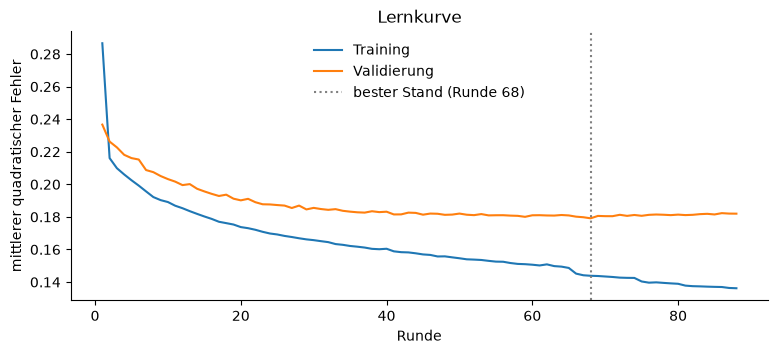

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(verlauf["runde"], verlauf["training"], label="Training")
ax.plot(verlauf["runde"], verlauf["validierung"], label="Validierung")
ax.axvline(beste_runde, color="grey", ls=":", label=f"bester Stand (Runde {beste_runde})")
ax.set_xlabel("Runde")
ax.set_ylabel("mittlerer quadratischer Fehler")
ax.set_title("Lernkurve")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Zeigt, wie der Fehler über die Runden sinkt. Laufen Training und Validierung weit
  auseinander, lernt das Netz die Trainingstage auswendig (Überanpassung).

**Was man sieht**

- Der Validierungsfehler fällt in den ersten 20 Runden steil und wird ab Runde 40 flach. Der beste Stand liegt in Runde 68.
- Der Trainingsfehler sinkt danach weiter, der Validierungsfehler nicht mehr. Ab hier würde das Netz anfangen, die Trainingstage auswendig zu lernen. Genau dafür ist das Early Stopping da: Es behält Runde 68.
- Auf der Grafikkarte dauert das gut 20 Sekunden, auf einer CPU einige Minuten.

Validierungsfehler je Tag: Median 0.140; gezeigt wird ein Wintertag mit 0.129


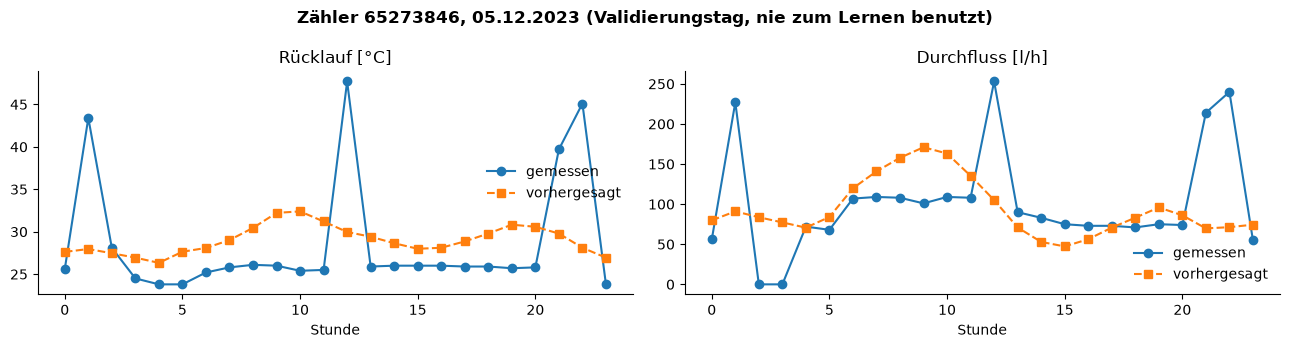

In [8]:
# Ein typischer Validierungstag im Winter: der mit dem mittleren Vorhersagefehler
modell.eval()
val_index = np.flatnonzero(ist_val)
with torch.no_grad():
    val_vorhersage = modell(eingang[val_index].to(GERAET), aussen_morgen[val_index].to(GERAET)).cpu().numpy()
fehler_je_tag = ((val_vorhersage - ziel[val_index].numpy()) ** 2).mean(axis=(1, 2))
im_winter = tage.loc[morgen[val_index], "tag"].dt.month.isin([12, 1, 2]).to_numpy()
kandidaten = np.flatnonzero(im_winter)
mitte = kandidaten[np.argsort(fehler_je_tag[kandidaten])[len(kandidaten) // 2]]
beispiel, vorhersage = val_index[mitte], val_vorhersage[mitte]
print(f"Validierungsfehler je Tag: Median {np.median(fehler_je_tag):.3f}; gezeigt wird ein Wintertag mit {fehler_je_tag[mitte]:.3f}")
tag_index = morgen[beispiel]
zaehler, datum = tage.loc[tag_index, "zaehler"], tage.loc[tag_index, "tag"]
i_rl, i_fl = KANAELE.index("ruecklauf"), KANAELE.index("durchfluss")
rl_vorh = vorhersage[:, i_rl] * streuung["ruecklauf"] + mittel["ruecklauf"]
fl_vorh = vorhersage[:, i_fl] * teiler["durchfluss"][zaehler]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(werte[tag_index, :, i_rl], "o-", label="gemessen")
axes[0].plot(rl_vorh, "s--", label="vorhergesagt")
axes[0].set_title("Rücklauf [°C]")
axes[1].plot(werte[tag_index, :, i_fl], "o-", label="gemessen")
axes[1].plot(fl_vorh, "s--", label="vorhergesagt")
axes[1].set_title("Durchfluss [l/h]")
for ax in axes:
    ax.set_xlabel("Stunde")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Zähler {zaehler}, {datum:%d.%m.%Y} (Validierungstag, nie zum Lernen benutzt)", fontweight="bold")
fig.tight_layout()
plt.show()

**Was macht diese Zelle?**
- Sagt alle Validierungstage vorher und sucht unter den Wintertagen den mit dem **mittleren**
  Fehler — kein Glanzbeispiel und kein Ausreißer.
- Rechnet die Skalierung zurück in °C und l/h.
- Das Netz soll den groben Verlauf treffen, nicht jede Stunde: Für das Embedding zählt,
  dass es das Typische einer Station erfasst.

## 5 · Embeddings: acht Zahlen je Tag, gemittelt je Station

Jetzt wird nur noch der Encoder gebraucht. Jeder vollständige Tag — auch die nach den
Begehungen — wird in seine acht Zahlen übersetzt. Je Zähler und Zeitraum ergibt der
Mittelwert über alle Tage eine Beschreibung der Station.

In [9]:
with torch.no_grad():
    kerne = torch.cat([modell.einbetten(torch.tensor(x[i:i + 4096]).to(GERAET)).cpu()
                       for i in range(0, len(x), 4096)]).numpy()
kern_tab = pd.DataFrame(kerne, columns=[f"z{i}" for i in range(kerne.shape[1])])
kern_tab = pd.concat([tage[["zaehler", "tag", "vorher"]], kern_tab], axis=1)

ZEITRAEUME = {"w2223": ("2022-10-01", "2023-04-01"), "w2324": ("2023-10-01", "2024-04-01"), "s2024": ("2024-06-01", "2024-09-01")}
MIN_TAGE = 30
teile = []
for name, (von, bis) in ZEITRAEUME.items():
    t = kern_tab[(kern_tab["tag"] >= von) & (kern_tab["tag"] < bis) & kern_tab["vorher"]]
    mittel = t.groupby("zaehler")[[f"z{i}" for i in range(8)]].mean()
    mittel = mittel[t.groupby("zaehler").size() >= MIN_TAGE]
    teile.append(mittel.add_prefix(f"lstm_{name}_"))
embedding = pd.concat(teile, axis=1)
print(f"Embeddings für {len(embedding)} Zähler; je Zeitraum vorhanden: "
      + ", ".join(f"{n} {embedding[f'lstm_{n}_z0'].notna().sum()}" for n in ZEITRAEUME))
embedding.round(2).head()

Embeddings für 93 Zähler; je Zeitraum vorhanden: w2223 43, w2324 90, s2024 84


,lstm_w2223_z0,lstm_w2223_z1,lstm_w2223_z2,lstm_w2223_z3,lstm_w2223_z4,lstm_w2223_z5,lstm_w2223_z6,lstm_w2223_z7,lstm_w2324_z0,lstm_w2324_z1,lstm_w2324_z2,lstm_w2324_z3,lstm_w2324_z4,lstm_w2324_z5,lstm_w2324_z6,lstm_w2324_z7,lstm_s2024_z0,lstm_s2024_z1,lstm_s2024_z2,lstm_s2024_z3,lstm_s2024_z4,lstm_s2024_z5,lstm_s2024_z6,lstm_s2024_z7
zaehler,,,,,,,,,,,,,,,,,,,,,,,,
41704231,-0.58,0.63,1.16,-1.26,-0.32,0.14,0.16,1.95,-0.63,0.62,1.03,-1.19,-0.22,0.13,0.16,1.91,-0.78,0.50,0.49,-0.94,0.14,0.10,0.18,1.57
41704232,-0.81,0.14,0.79,-0.11,0.12,-0.06,0.13,0.61,-0.76,0.69,0.96,-1.28,-0.21,0.13,0.17,2.00,-0.69,0.49,0.54,-0.72,0.12,0.20,0.15,1.43
53198226,-0.78,0.19,-0.04,0.14,-0.16,0.02,-0.17,-0.70,-0.27,0.16,0.02,0.12,-0.22,-0.19,-0.31,-1.01,-1.20,0.19,-0.21,0.11,0.41,-0.05,0.47,-0.49
58177363,-0.37,0.36,0.32,0.13,-0.49,-0.28,-0.59,-0.63,-0.34,0.39,0.40,0.12,-0.44,-0.27,-0.42,-0.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58177384,-0.21,0.26,-0.67,0.00,0.47,-0.24,-0.56,-0.76,-0.35,0.05,-0.22,-0.34,-0.05,-0.37,-0.13,-0.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Was macht diese Zelle?**
- Übersetzt alle Tage in Stapeln von 4096 mit `modell.einbetten()`.
- Bildet je Zähler den Mittelwert über drei Zeiträume: Winter 22/23, Winter 23/24 und
  Sommer 2024, jeweils nur vor der Begehung und nur, wenn es mindestens 30 Tage sind.
- Heraus kommt eine Tabelle mit einer Zeile je Zähler und 3 × 8 Spalten.

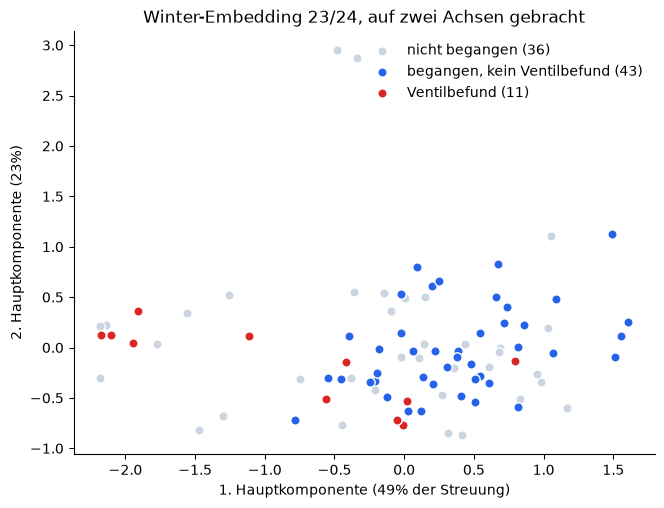

In [10]:
w = embedding.filter(like="lstm_w2324_").dropna()
pca = PCA(n_components=2).fit(w)
punkte = pd.DataFrame(pca.transform(w), index=w.index, columns=["pc1", "pc2"]).join(labels["ventil"])
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for wert, farbe, name in ((np.nan, "#CBD5E1", "nicht begangen"), (False, "#2563EB", "begangen, kein Ventilbefund"), (True, "#DC2626", "Ventilbefund")):
    teil = punkte[punkte["ventil"].isna()] if wert is np.nan else punkte[punkte["ventil"] == wert]
    ax.scatter(teil["pc1"], teil["pc2"], color=farbe, s=45, label=f"{name} ({len(teil)})", edgecolor="white")
ax.set_xlabel(f"1. Hauptkomponente ({pca.explained_variance_ratio_[0]:.0%} der Streuung)")
ax.set_ylabel(f"2. Hauptkomponente ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Winter-Embedding 23/24, auf zwei Achsen gebracht")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Acht Zahlen kann man nicht zeichnen. Die Hauptkomponentenanalyse (PCA) sucht die zwei
  Richtungen, in denen die Stationen am stärksten streuen, und zeigt die Stationen darin.
- Gefärbt nach dem Ventilbefund. Das Netz hat diese Farben nie gesehen.

**Was man sieht**

- Links (1. Hauptkomponente unter −1) sitzt eine eigene Gruppe. Darin liegen **5 der 11 Ventilfälle** und **keine einzige** begangene Station ohne Befund. Die übrigen 6 Ventilfälle liegen in der Mitte zwischen den anderen.
- In der linken Gruppe liegen außerdem **8 nicht begangene** Stationen (grau). Wenn diese Gruppe das Ventilbild ist, wären das die ersten Kandidaten für eine Begehung. Notebook 22 rechnet das ordentlich mit einem Modell nach.
- Die beiden Achsen fassen 72 % der Streuung der acht Zahlen. Das Bild zeigt also das Wesentliche, aber nicht alles.

## 6 · Prüfung ohne Labels: Erkennt das Netz eine Station im nächsten Winter wieder?

Bevor die Befunde ins Spiel kommen, eine Prüfung, die keine Labels braucht: Wenn das
Embedding wirklich die **Station** beschreibt und nicht den Zufall eines Winters, dann
sollte das Winter-Embedding 23/24 einer Station ihrem eigenen von 22/23 am nächsten
liegen. Bei reinem Raten träfe man bei n Stationen in 1/n der Fälle.

In [11]:
beide = embedding[[f"lstm_w2223_z{i}" for i in range(8)] + [f"lstm_w2324_z{i}" for i in range(8)]].dropna()
alt = beide.filter(like="w2223").to_numpy()
neu = beide.filter(like="w2324").to_numpy()
abstand = np.linalg.norm(neu[:, None, :] - alt[None, :, :], axis=2)   # Station i (23/24) gegen Station j (22/23)
rang = (abstand < np.diag(abstand)[:, None]).sum(axis=1) + 1          # 1 = die eigene Station ist die nächste
print(f"{len(beide)} Zähler mit beiden Wintern")
print(f"Wiedererkannt (eigene Station am nächsten): {(rang == 1).mean():.0%}   Zufall wäre {1 / len(beide):.0%}")
print(f"Eigene Station unter den 3 nächsten:        {(rang <= 3).mean():.0%}   Zufall wäre {3 / len(beide):.0%}")

43 Zähler mit beiden Wintern
Wiedererkannt (eigene Station am nächsten): 88%   Zufall wäre 2%
Eigene Station unter den 3 nächsten:        93%   Zufall wäre 7%


**Was macht diese Zelle?**
- Nimmt die Zähler, die in beiden Wintern genug Tage haben.
- Rechnet für jede Station den Abstand ihres 23/24-Embeddings zu allen 22/23-Embeddings und
  zählt, wie viele fremde Stationen näher liegen als die eigene.

**Ergebnis**

- **88 %** der 43 Stationen werden im nächsten Winter wiedererkannt: Ihr Embedding 23/24 liegt dem eigenen von 22/23 näher als jedem fremden. Zufall wären 2 %. Unter den drei nächsten ist die eigene Station in 93 % der Fälle.
- Das Embedding beschreibt also die **Station**, nicht das Wetter oder den Zufall eines Winters. Erst das macht es als Merkmal für die Fehlersuche brauchbar.
- Diese Prüfung braucht keine Labels. Deshalb durfte sie in der Vorarbeit zur Auswahl der Architektur dienen: Gewählt wurde die Variante, die Stationen am besten wiedererkennt, und nicht die mit der besten AUC an den Befunden. Sonst hätte die Auswahl die Befunde auswendig gelernt.

## 7 · Fehlererkennung: Welche Station hatte bei der Begehung einen Befund?

Jetzt kommen die Labels. Auf den Embeddings lernt eine **logistische Regression**, ob
eine Station einen Ventil- bzw. Dämmungsbefund hatte. Damit die Prüfung ehrlich ist,
gilt:

* **Verschachtelte Kreuzvalidierung.** Außen wird jede Station einmal ausgelassen
  (Leave-one-out), gelernt wird auf den übrigen. Innen wählt eine 4-fache
  Kreuzvalidierung nur auf diesen übrigen Stationen die Regularisierung `C`. Die
  ausgelassene Station sieht weder das Modell noch die Wahl von `C`.
* **AUC mit Unsicherheit.** Die AUC ist die Wahrscheinlichkeit, dass eine zufällige
  Station mit Befund vor einer zufälligen ohne Befund eingeordnet wird (0,5 = Raten,
  1 = perfekt). Das Intervall kommt aus 2000 Bootstrap-Ziehungen der Stationen.
* **Precision@10:** Wie viele der zehn am höchsten eingestuften Stationen hatten
  wirklich einen Befund? Das ist die Frage aus der Praxis: Welche zehn begehe ich zuerst?

In [12]:
def verschachtelt(X, y, gruppen=None):
    # Vorhersage je Station aus einem Modell, das diese Station nie gesehen hat
    modell = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                           LogisticRegression(class_weight="balanced", max_iter=5000))
    suche = GridSearchCV(modell, {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]},
                         cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
    aussen = LeaveOneOut() if gruppen is None else LeaveOneGroupOut()
    return cross_val_predict(suche, X, y, cv=aussen, groups=gruppen, method="predict_proba", n_jobs=-1)[:, 1]


def auc_mit_intervall(y, score, n=2000):
    y, score = np.asarray(y), np.asarray(score)
    rng = np.random.default_rng(SEED)
    ziehungen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            ziehungen.append(roc_auc_score(y[i], score[i]))
    return roc_auc_score(y, score), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def precision_at_k(y, score, k=10):
    return np.asarray(y)[np.argsort(-np.asarray(score))[:k]].mean()

**Was macht diese Zelle?**
- `verschachtelt()`: Die Pipeline füllt Lücken mit dem Median, standardisiert und lernt die
  logistische Regression. `GridSearchCV` ist die innere Schleife, die `C` wählt;
  `cross_val_predict` mit `LeaveOneOut` ist die äußere. Alles läuft im Lernteil — auch der
  Median und die Standardisierung.
- `class_weight="balanced"`: Bei 11 Ventilfällen unter 54 Stationen würde ein Modell sonst
  lernen, dass „kein Befund“ fast immer stimmt.
- `auc_mit_intervall()` und `precision_at_k()` sind die beiden Gütemaße.

In [13]:
KENNZAHLEN = [c for c in kz.columns if not c.startswith("stunden_")]
WINTER_KZ = [c for c in KENNZAHLEN if c.startswith("winter_") or c in ("auslastung", "anteil_volumenstrom", "streubreite_betriebspunkte", "ruecklauf_lastgewichtet")]
LSTM_WINTER = [f"lstm_w2324_z{i}" for i in range(8)]
LSTM_SOMMER = [f"lstm_s2024_z{i}" for i in range(8)]

tabelle = labels[["ventil", "daemmung", "strasse_gruppe"]].join(kz).join(embedding)
basis = tabelle.dropna(subset=LSTM_WINTER + ["sommer_durchlauf_anteil"])
print(f"Prüfbasis: {len(basis)} begangene Zähler mit Winter-Embedding und Sommerwerten "
      f"(Ventil {int(basis['ventil'].sum())}, Dämmung {int(basis['daemmung'].sum())})")
print(f"Ausgeschlossen: {len(labels) - len(basis)} begangene Zähler ohne genug Winter- oder Sommertage")

VERFAHREN = {
    "Kennzahlen (alle)": KENNZAHLEN,
    "LSTM Winter + Sommer": LSTM_WINTER + LSTM_SOMMER,
    "Kennzahlen + LSTM": KENNZAHLEN + LSTM_WINTER + LSTM_SOMMER,
    "nur Winter: Kennzahlen": WINTER_KZ,
    "nur Winter: LSTM": LSTM_WINTER,
    "nur Winter: Kennzahlen + LSTM": WINTER_KZ + LSTM_WINTER,
}
scores = {}
for ziel in ("ventil", "daemmung"):
    y = basis[ziel].astype(int).to_numpy()
    scores[(ziel, "Sommernacht-Regel (ohne Lernen)")] = basis["sommer_durchlauf_anteil"].to_numpy()
    for name, spalten in VERFAHREN.items():
        scores[(ziel, name)] = verschachtelt(basis[spalten], y)

zeilen = []
for (ziel, name), s in scores.items():
    y = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(y, s)
    zeilen.append({"Ziel": ziel, "Verfahren": name, "AUC": auc, "unten": unten, "oben": oben, "P@10": precision_at_k(y, s)})
ergebnis = pd.DataFrame(zeilen)
ergebnis.round(2)

Prüfbasis: 53 begangene Zähler mit Winter-Embedding und Sommerwerten (Ventil 11, Dämmung 22)
Ausgeschlossen: 3 begangene Zähler ohne genug Winter- oder Sommertage


,Ziel,Verfahren,AUC,unten,oben,P@10
0,ventil,Sommernacht-Regel (ohne Lernen),0.85,0.68,0.98,0.7
1,ventil,Kennzahlen (alle),0.79,0.57,0.97,0.6
2,ventil,LSTM Winter + Sommer,0.84,0.70,0.95,0.6
3,ventil,Kennzahlen + LSTM,0.89,0.78,0.98,0.8
4,ventil,nur Winter: Kennzahlen,0.68,0.44,0.89,0.5
5,ventil,nur Winter: LSTM,0.86,0.74,0.95,0.5
6,ventil,nur Winter: Kennzahlen + LSTM,0.81,0.63,0.95,0.6
7,daemmung,Sommernacht-Regel (ohne Lernen),0.57,0.40,0.73,0.6
8,daemmung,Kennzahlen (alle),0.68,0.52,0.84,0.9
9,daemmung,LSTM Winter + Sommer,0.70,0.54,0.86,1.0


**Was macht diese Zelle?**
- Legt die Merkmalsgruppen fest: alle Kennzahlen aus Notebook 18, die LSTM-Embeddings aus
  Winter und Sommer, beides zusammen, und drei Varianten **nur mit Winterdaten**.
- Die Prüfbasis ist für alle Verfahren gleich: begangene Zähler mit Winter-Embedding und
  Sommerwerten. Sonst wären die AUCs nicht vergleichbar.
- Die **Sommernacht-Regel** ist die Messlatte ohne Lernen: Stationen werden nur nach dem
  Anteil der Sommernächte mit Durchfluss sortiert.

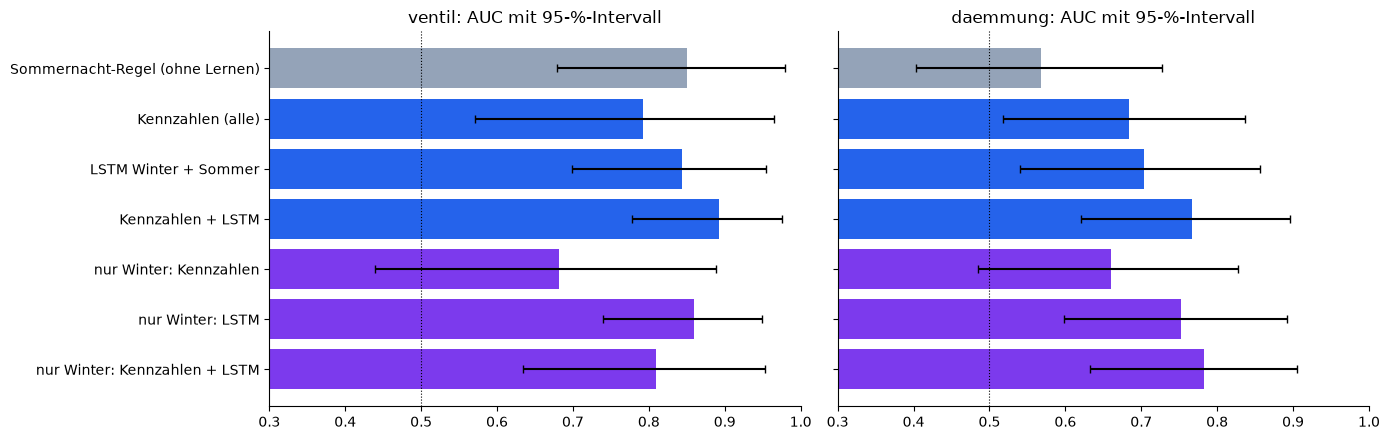

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, ziel in zip(axes, ("ventil", "daemmung")):
    t = ergebnis[ergebnis["Ziel"] == ziel].reset_index(drop=True)
    farben = ["#94A3B8" if "Regel" in v else "#7C3AED" if v.startswith("nur Winter") else "#2563EB" for v in t["Verfahren"]]
    ax.barh(t["Verfahren"], t["AUC"], xerr=[t["AUC"] - t["unten"], t["oben"] - t["AUC"]], color=farben, capsize=3)
    ax.axvline(0.5, color="black", lw=0.8, ls=":")
    ax.set_xlim(0.3, 1.0)
    ax.invert_yaxis()
    ax.set_title(f"{ziel}: AUC mit 95-%-Intervall")
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

**Was macht diese Zelle?**
- Zeigt die AUC je Verfahren mit dem Bootstrap-Intervall. Grau: die Regel ohne Lernen,
  blau: mit Sommerdaten, violett: nur Winterdaten. Die gepunktete Linie ist Raten.

**Ergebnis**

**Ventil** (11 von 53, Basisrate 21 %)

- **Mit Sommerdaten ist das Ventil leicht:** Schon die Regel ohne Lernen kommt auf AUC 0,85. Kennzahlen und LSTM zusammen erreichen 0,89, und unter den zehn höchsten Stationen sind 8 echte Ventilfälle (Zufall: 2).
- **Nur mit Winterdaten trennt sich das Feld:** Die Winter-Kennzahlen kommen auf 0,68, das LSTM-Embedding auf **0,86**, fast so gut wie mit Sommerdaten.
- Das ist der eigentliche Gewinn des LSTM: Ein undichtes Ventil zeigt sich im Sommer offen (Durchfluss in der Nacht). Im Winter geht es im Heizbetrieb unter, und eine handgebaute Kennzahl findet es kaum. Das Netz hat aus den Stundenverläufen gelernt, wie eine solche Station auch im Winter aussieht.

**Dämmung** (22 von 53, Basisrate 42 %)

- Die Sommernacht-Regel sagt über Dämmung nichts (0,57). Das passt, sie misst ja das Ventil.
- Kennzahlen allein 0,68, LSTM allein 0,70, **beides zusammen 0,77**. Unter den zehn höchsten Stationen sind 8 bis 10 mit Dämmungsbefund (Zufall: 4).

### Ist der Unterschied belegt?

Zwei AUCs mit überlappenden Intervallen können trotzdem verschieden sein, weil beide
auf **denselben** Stationen gemessen werden. Richtig ist der **gepaarte** Vergleich:
In jeder Bootstrap-Ziehung werden beide Verfahren auf derselben Stichprobe bewertet
und die Differenz gemerkt. Schließt das Intervall der Differenz die 0 aus, ist der
Unterschied belegt.

In [15]:
def auc_differenz(y, a, b, n=2000):
    rng = np.random.default_rng(SEED)
    differenzen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            differenzen.append(roc_auc_score(y[i], a[i]) - roc_auc_score(y[i], b[i]))
    return roc_auc_score(y, a) - roc_auc_score(y, b), np.quantile(differenzen, 0.025), np.quantile(differenzen, 0.975)


VERGLEICHE = [
    ("ventil", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
    ("ventil", "nur Winter: LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
]
zeilen = []
for ziel, a, b in VERGLEICHE:
    y = basis[ziel].astype(int).to_numpy()
    d, unten, oben = auc_differenz(y, scores[(ziel, a)], scores[(ziel, b)])
    zeilen.append({"Ziel": ziel, "Verfahren": a, "gegen": b, "Differenz": d, "unten": unten, "oben": oben,
                   "belegt": "ja" if unten > 0 or oben < 0 else "nein"})
pd.DataFrame(zeilen).round(2)

,Ziel,Verfahren,gegen,Differenz,unten,oben,belegt
0,ventil,nur Winter: LSTM,nur Winter: Kennzahlen,0.18,0.01,0.38,ja
1,ventil,nur Winter: LSTM,Sommernacht-Regel (ohne Lernen),0.01,-0.12,0.16,nein
2,ventil,Kennzahlen + LSTM,Sommernacht-Regel (ohne Lernen),0.04,-0.06,0.17,nein
3,ventil,Kennzahlen + LSTM,Kennzahlen (alle),0.10,-0.02,0.26,nein
4,daemmung,Kennzahlen + LSTM,Kennzahlen (alle),0.08,-0.02,0.21,nein
5,daemmung,nur Winter: LSTM,nur Winter: Kennzahlen,0.09,-0.06,0.25,nein


**Was macht diese Zelle?**
- `auc_differenz()` zieht 2000-mal eine Stichprobe der Stationen und rechnet in jeder
  Ziehung die AUC beider Verfahren auf genau denselben Stationen.
- Die Tabelle zeigt die Differenz mit 95-%-Intervall und ob sie die 0 ausschließt.

**Ergebnis**

- **Belegt ist eine Aussage:** Mit Winterdaten ist das LSTM beim Ventil besser als die Kennzahlen, um 0,18 (Intervall 0,01 bis 0,38). Das Intervall ist breit, schließt die 0 aber aus.
- **Mit Sommerdaten ist das LSTM nicht belegt besser als die Regel** (+0,01 bzw. +0,04). Wenn man den Sommer abwarten kann, reicht die einfache Regel.
- **Bei der Dämmung** bringt das LSTM zu den Kennzahlen +0,08 dazu, das Intervall reicht aber bis −0,02. Mit 53 Stationen lässt sich ein Unterschied dieser Größe nicht absichern.

In [16]:
# Von Hand nachgerechnet: die AUC ist der Anteil der Paare (Befund, kein Befund),
# in denen die Station mit Befund den höheren Score hat (Gleichstand zählt halb).
y = basis["ventil"].astype(int).to_numpy()
s = scores[("ventil", "nur Winter: LSTM")]
pos, neg = s[y == 1], s[y == 0]
paare = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
print(f"{len(pos)} × {len(neg)} = {len(pos) * len(neg)} Paare, davon richtig herum: {paare:.3f}")
assert np.isclose(paare, roc_auc_score(y, s))
print("stimmt mit roc_auc_score überein")

# Und noch einmal mit ganzen Straßen statt einzelnen Stationen ausgelassen
gruppen = basis["strasse_gruppe"].to_numpy()
for ziel, name in (("ventil", "nur Winter: LSTM"), ("ventil", "Kennzahlen + LSTM"), ("daemmung", "Kennzahlen + LSTM")):
    yz = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(yz, verschachtelt(basis[VERFAHREN[name]], yz, gruppen))
    print(f"Straßen ausgelassen – {ziel:8s} {name:28s} AUC {auc:.2f} [{unten:.2f}; {oben:.2f}]")

11 × 42 = 462 Paare, davon richtig herum: 0.859
stimmt mit roc_auc_score überein


Straßen ausgelassen – ventil   nur Winter: LSTM             AUC 0.86 [0.72; 0.97]


Straßen ausgelassen – ventil   Kennzahlen + LSTM            AUC 0.84 [0.66; 0.97]


Straßen ausgelassen – daemmung Kennzahlen + LSTM            AUC 0.80 [0.66; 0.91]


**Was macht diese Zelle?**
- Rechnet eine AUC ohne scikit-learn nach: über alle Paare aus einer Station mit und einer
  ohne Befund zählen, wie oft die mit Befund vorne liegt.
- Wiederholt drei Prüfungen so, dass immer eine **ganze Straße** ausgelassen wird. Begangen
  wurde Straße für Straße, und Nachbarhäuser ähneln sich. Bleibt die AUC ähnlich hoch,
  hat das Modell nicht nur Nachbarn wiedererkannt.

**Ergebnis**

- Die AUC von Hand über die 462 Paare stimmt mit `roc_auc_score` überein.
- **Ganze Straßen auslassen ändert kaum etwas:** Ventil im Winter 0,86 (wie vorher), Ventil mit allen Daten 0,84 (vorher 0,89), Dämmung 0,80 (vorher 0,77). Das Modell erkennt also nicht nur Nachbarhäuser wieder, deren Straße schon im Training war.

## 8 · Ergebnis speichern

In [17]:
embedding.to_csv(PROCESSED / "lstm_embedding.csv")
oof = pd.DataFrame({f"{ziel} | {name}": s for (ziel, name), s in scores.items()}, index=basis.index)
oof.to_csv(PROCESSED / "lstm_scores.csv")
print(f"lstm_embedding.csv: {embedding.shape},  lstm_scores.csv: {oof.shape}")

lstm_embedding.csv: (93, 24),  lstm_scores.csv: (53, 14)


**Was macht diese Zelle?**
- Speichert die Embeddings aller Zähler, auch der nicht begangenen. Notebook 22 nutzt sie als
  Merkmale neben den Kennzahlen.
- Speichert die Vorhersagen aus der Prüfung, damit sie sich später ohne neues Lernen
  vergleichen lassen.

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

Ein LSTM (117.000 Gewichte, 20 Sekunden Training auf der GPU), das aus einem Tag einer Station den nächsten vorhersagt und dabei jede Station in **acht Zahlen** beschreibt. Gelernt nur aus Tagen vor den Begehungen und ohne ein einziges Label. Die Embeddings aller 93 Zähler liegen in `lstm_embedding.csv`.

| Prüfung | Ergebnis | Bewertung |
|---|---|---|
| Wiedererkennung über zwei Winter (ohne Labels) | 88 % (Zufall 2 %) | **bestanden** |
| Ventil, alle Daten | AUC 0,89 [0,78; 0,98], P@10 0,8 | **stark**, aber nicht belegt besser als die Sommernacht-Regel (0,85) |
| Ventil, nur Winter | LSTM 0,86 gegen Kennzahlen 0,68 | **belegt besser** (+0,18 [0,01; 0,38]) |
| Dämmung | AUC 0,77 [0,62; 0,90], P@10 0,9 | **wahrscheinlich**, LSTM-Beitrag nicht abgesichert |
| Ganze Straßen ausgelassen | 0,80–0,86 | **bestanden** |

### Wie das Ergebnis einzuordnen ist

- **Der Wert des LSTM liegt im Winter.** Ein undichtes Ventil ist im Sommer mit einer einfachen Regel zu sehen. Das LSTM erkennt es schon im Winter, also Monate früher und in der Zeit, in der der Schaden am größten ist.
- **Dämmung ist erkennbar, aber schwächer.** 0,77 ist deutlich besser als Raten. Mit 53 Stationen bleibt das Intervall aber breit.
- **Abweichung von der Vorarbeit:** Lokal, mit einer etwas anderen Datenaufbereitung, lag das Ventil im Winter bei bis zu 0,96. Hier sind es 0,86. Die Richtung ist dieselbe, die Zahl hängt an Details der Aufbereitung und an wenigen Stationen.
- **Schwach:** 11 Ventilfälle. Jede einzelne Station verschiebt die AUC um mehrere Hundertstel.

Notebook 21 nutzt dieselbe Idee in die andere Richtung: Ein LSTM sagt den nächsten Tag vorher und schlägt Alarm, wenn die Station davon abweicht. Notebook 22 nimmt die Embeddings als Merkmale für XGBoost und alle Fehlerarten.